# Análise Estatística do Mercado de Videogames

## 0. Contexto, pergunta de negócio e escolha do dataset

**Dataset.** Base pública de vendas de videogames que combina vendas por região (em **milhões de cópias**, não receita) com notas da crítica especializada (`Critic_Score`, 0 a 100) e do público (`User_Score`, 0 a 10) e o número de avaliações de cada lado.

**Por que este dataset.** Ele permite explorar relações entre variáveis quantitativas e qualitativas (nota, volume de avaliações, gênero, plataforma, ano) e oferece decisões concretas para um estúdio ou publisher: em que gêneros investir e quanto vale a recepção da crítica.

**Pergunta de negócio.** Quais fatores observáveis (recepção da crítica e do público, volume de avaliações, gênero) se associam a maiores vendas globais, e com que confiabilidade é possível prever vendas a partir deles?

**Estrutura do notebook.**
1. Carregamento, diagnóstico de ausentes e tratamento
2. Engenharia de variáveis
3. Análise exploratória
4. Testes de hipóteses e intervalos de confiança
5. Regressão linear múltipla, diagnóstico, validação e previsão
6. Conclusões, recomendações e limitações
7. Exportação para o dashboard

In [1]:
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:.4g}')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

## 1. Carregamento, diagnóstico de ausentes e tratamento

Antes de decidir qualquer tratamento, quantificamos quanto falta em cada coluna. `User_Score` vem como texto porque contém o rótulo `tbd` (*to be determined*): a nota do público ainda não havia sido definida. Convertemos para número com `errors='coerce'`, o que transforma `tbd` em ausente.

In [2]:
df = pd.read_csv('Video_Games.csv')
print('Linhas e colunas:', df.shape)
print('Registros com User_Score igual a tbd:', (df['User_Score'] == 'tbd').sum())

df['User_Score'] = pd.to_numeric(df['User_Score'], errors='coerce')

ausentes = pd.DataFrame({'ausentes': df.isna().sum(), 'percentual': df.isna().mean() * 100})
display(ausentes[ausentes['ausentes'] > 0].sort_values('ausentes', ascending=False))

Linhas e colunas: (16928, 17)
Registros com User_Score igual a tbd: 2441


,ausentes,percentual
User_Score,9210,54.41
User_Count,9210,54.41
Critic_Count,8668,51.21
Critic_Score,8668,51.21
Rating,6836,40.38
Developer,6688,39.51
Year_of_Release,273,1.613
Publisher,55,0.3249
Name,2,0.01181
Genre,2,0.01181


### Decisão de tratamento e justificativa

* **Estratégia: análise de casos completos** nas colunas usadas (`Critic_Score`, `User_Score`, `Year_of_Release`, `Genre`, `Publisher`).
* **Por que não imputar as notas.** Cerca de metade dos jogos não tem nota da crítica. Essa ausência não é aleatória: jogos de menor porte tendem a não ser avaliados. Imputar notas criaria valores artificiais justamente na variável explicativa central do estudo e distorceria as relações que queremos medir.
* **Por que excluir `Year_of_Release`, `Genre` e `Publisher` ausentes.** São poucos registros e `Genre` é indispensável para as comparações entre gêneros.
* **Custo da decisão.** A base encolhe bastante e a amostra restante é composta por jogos que receberam avaliações, que tendem a ser mais vendidos. O bloco abaixo mede esse viés de seleção. As conclusões, portanto, valem para jogos avaliados, não para todo o mercado.

In [3]:
colunas_criticas = ['Critic_Score', 'User_Score', 'Year_of_Release', 'Genre', 'Publisher']
df_clean = df.dropna(subset=colunas_criticas).copy()
df_clean['Year_of_Release'] = df_clean['Year_of_Release'].astype(int)

print('Linhas antes:', len(df), '| depois:', len(df_clean))
print(f'Percentual descartado: {(1 - len(df_clean) / len(df)) * 100:.1f}%')
print('Ausentes remanescentes em Critic_Count e User_Count:')
print(df_clean[['Critic_Count', 'User_Count']].isna().sum().to_string())

comparacao = pd.DataFrame({
    'Base original': df['Global_Sales'].describe(),
    'Base tratada': df_clean['Global_Sales'].describe()
})
display(comparacao)

Linhas antes: 16928 | depois: 7007
Percentual descartado: 58.6%
Ausentes remanescentes em Critic_Count e User_Count:
Critic_Count    0
User_Count      0


,Base original,Base tratada
count,1.693e+04,7007
mean,0.5395,0.7798
std,1.551,1.956
min,0.01,0.01
25%,0.06,0.11
50%,0.17,0.3
75%,0.49,0.74
max,82.53,82.53


## 2. Engenharia de variáveis

| Variável | Definição | Justificativa |
|---|---|---|
| `User_Score_100` | `User_Score` × 10 | Coloca a nota do público na mesma escala (0 a 100) da crítica, permitindo comparação direta e teste pareado. |
| `Score_Diff` | `Critic_Score` − `User_Score_100` | Quantifica o descolamento entre crítica e público. |
| `Sucesso_Comercial` | Alto Sucesso se `Global_Sales` ≥ 1,0 milhão | Limiar de 1 milhão de cópias como marco comercial usual; transforma a variável contínua em categoria para análise descritiva. |
| `Log_Sales` | log(1 + `Global_Sales`) | As vendas são extremamente assimétricas à direita; o log estabiliza a variância e aproxima a distribuição dos resíduos da normalidade. O `1 +` evita log de zero. |
| `Log_Critic_Count`, `Log_User_Count` | log(1 + contagem) | As contagens de avaliações também são assimétricas; o log reduz a influência de poucos jogos com contagens enormes. |

In [4]:
df_clean['User_Score_100'] = df_clean['User_Score'] * 10
df_clean['Score_Diff'] = df_clean['Critic_Score'] - df_clean['User_Score_100']
df_clean['Sucesso_Comercial'] = np.where(df_clean['Global_Sales'] >= 1.0, 'Alto Sucesso', 'Baixo Sucesso')
df_clean['Log_Sales'] = np.log1p(df_clean['Global_Sales'])
df_clean['Log_Critic_Count'] = np.log1p(df_clean['Critic_Count'])
df_clean['Log_User_Count'] = np.log1p(df_clean['User_Count'])

display(df_clean['Sucesso_Comercial'].value_counts().to_frame('jogos').assign(proporcao=lambda t: t['jogos'] / t['jogos'].sum()))
df_clean.info()

,jogos,proporcao
Sucesso_Comercial,,
Baixo Sucesso,5679,0.8105
Alto Sucesso,1328,0.1895


<class 'pandas.DataFrame'>
Index: 7007 entries, 0 to 16926
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              7007 non-null   int64  
 1   Name               7007 non-null   str    
 2   Platform           7007 non-null   str    
 3   Year_of_Release    7007 non-null   int64  
 4   Genre              7007 non-null   str    
 5   Publisher          7007 non-null   str    
 6   NA_Sales           7007 non-null   float64
 7   EU_Sales           7007 non-null   float64
 8   JP_Sales           7007 non-null   float64
 9   Other_Sales        7007 non-null   float64
 10  Global_Sales       7007 non-null   float64
 11  Critic_Score       7007 non-null   float64
 12  Critic_Count       7007 non-null   float64
 13  User_Score         7007 non-null   float64
 14  User_Count         7007 non-null   float64
 15  Developer          7003 non-null   str    
 16  Rating             6938 non-null   str 

## 3. Análise exploratória

### 3.1 Estatísticas descritivas e desempenho por gênero

In [5]:
variaveis_desc = ['Global_Sales', 'Critic_Score', 'User_Score_100', 'Score_Diff', 'Critic_Count', 'User_Count']
display(df_clean[variaveis_desc].describe().T.assign(assimetria=df_clean[variaveis_desc].skew()))

resumo_genero = (
    df_clean.groupby('Genre')['Global_Sales']
    .agg(jogos='count', media='mean', mediana='median', desvio_padrao='std')
    .assign(prop_alto_sucesso=df_clean.groupby('Genre')['Sucesso_Comercial'].apply(lambda s: (s == 'Alto Sucesso').mean()))
    .sort_values('media', ascending=False)
)
display(resumo_genero)

,count,mean,std,min,25%,50%,75%,max,assimetria
Global_Sales,7007,0.7798,1.956,0.01,0.11,0.3,0.74,82.53,15.9
Critic_Score,7007,70.31,13.86,13,62,72,81,98,-0.743
User_Score_100,7007,71.85,14.39,5,65,75,82,96,-1.212
Score_Diff,7007,-1.536,12.97,-62,-9,-2,5,66,0.3588
Critic_Count,7007,28.89,19.2,3,14,24,39,113,1.031
User_Count,7007,175.6,586.6,4,11,27,90,1.066e+04,8.6


,jogos,media,mediana,desvio_padrao,prop_alto_sucesso
Genre,,,,,
Misc,394,1.104,0.39,2.495,0.2462
Shooter,888,0.9551,0.35,1.863,0.232
Platform,411,0.9472,0.36,2.416,0.2311
Sports,972,0.8731,0.4,3.125,0.2006
Racing,596,0.8349,0.28,2.252,0.1997
Action,1667,0.735,0.29,1.469,0.186
Role-Playing,725,0.7102,0.26,1.246,0.171
Fighting,388,0.6906,0.34,1.159,0.1985
Simulation,305,0.6758,0.31,1.225,0.1738


### 3.2 Distribuição da variável resposta

**Objetivo:** verificar a forma da distribuição de `Global_Sales` para decidir se a variável precisa de transformação antes dos testes e da regressão.

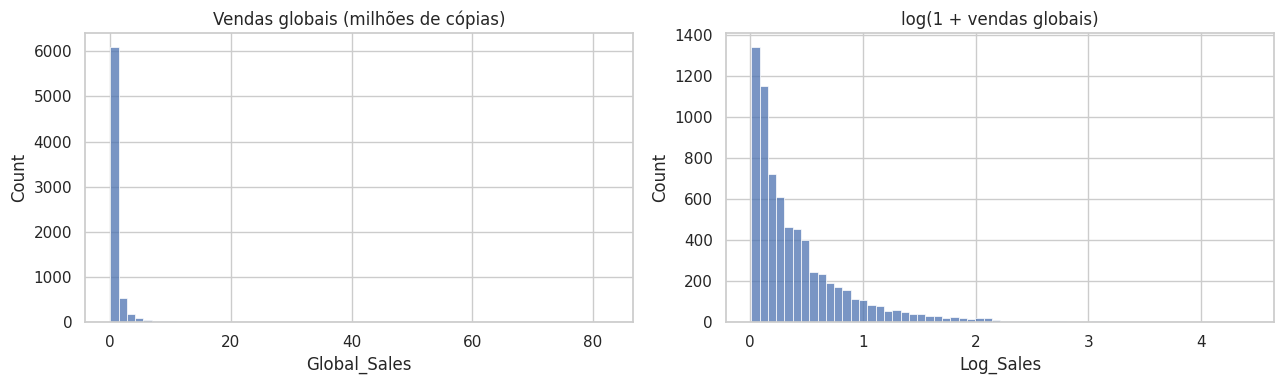

Assimetria de Global_Sales: 15.9
Assimetria de Log_Sales: 2.23


In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_clean['Global_Sales'], bins=60, ax=eixos[0])
eixos[0].set_title('Vendas globais (milhões de cópias)')
sns.histplot(df_clean['Log_Sales'], bins=60, ax=eixos[1])
eixos[1].set_title('log(1 + vendas globais)')
plt.tight_layout()
plt.show()

print('Assimetria de Global_Sales:', round(stats.skew(df_clean['Global_Sales']), 2))
print('Assimetria de Log_Sales:', round(stats.skew(df_clean['Log_Sales']), 2))

### 3.3 Relação entre notas, avaliações e vendas

**Objetivo:** investigar visualmente a relação entre cada variável explicativa e as vendas (escala log no eixo y) antes de ajustar qualquer modelo.

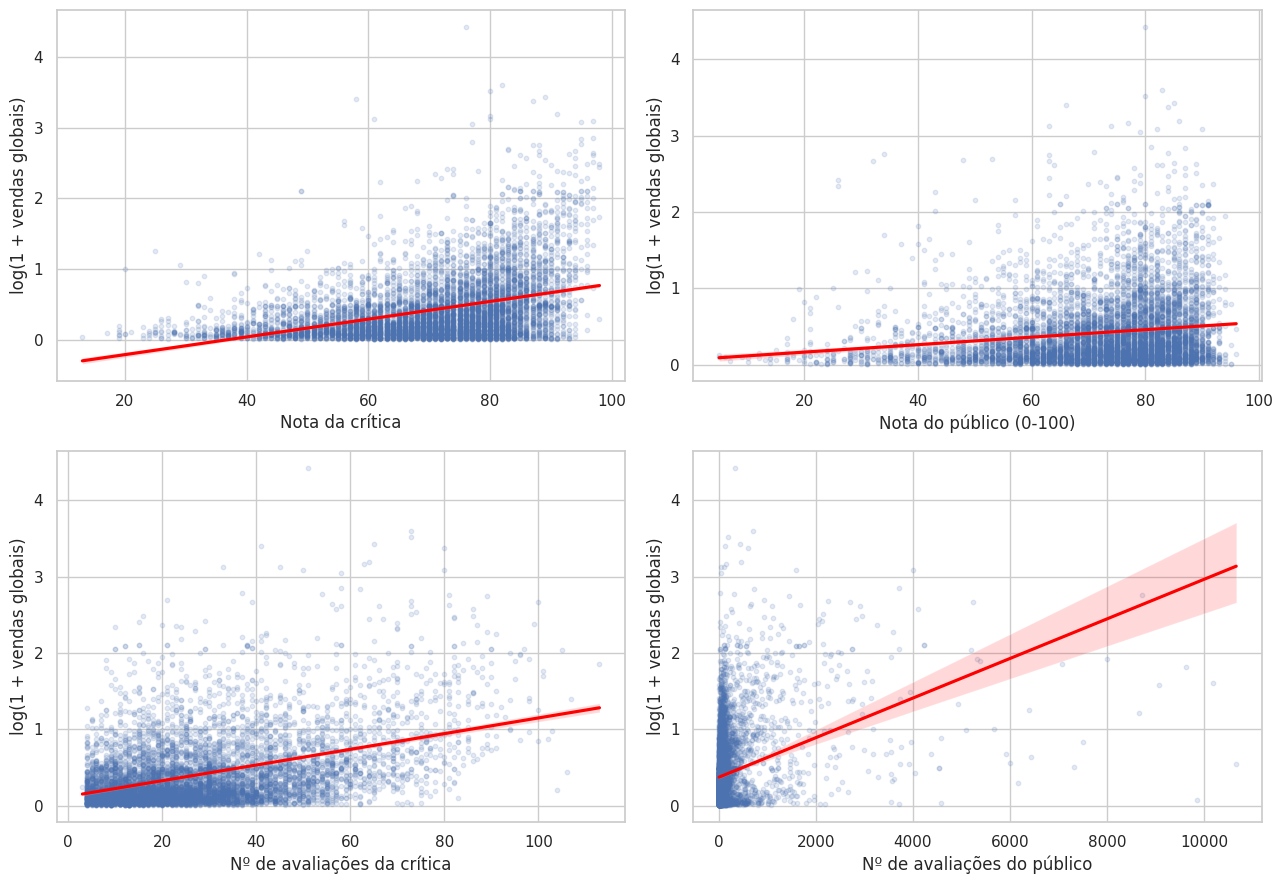

In [7]:
explicativas = [('Critic_Score', 'Nota da crítica'), ('User_Score_100', 'Nota do público (0-100)'),
                ('Critic_Count', 'Nº de avaliações da crítica'), ('User_Count', 'Nº de avaliações do público')]
fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
for eixo, (coluna, rotulo) in zip(eixos.ravel(), explicativas):
    sns.regplot(data=df_clean, x=coluna, y='Log_Sales', ax=eixo,
                scatter_kws={'alpha': 0.15, 's': 10}, line_kws={'color': 'red'})
    eixo.set_xlabel(rotulo)
    eixo.set_ylabel('log(1 + vendas globais)')
plt.tight_layout()
plt.show()

### 3.4 Vendas por gênero

**Objetivo:** comparar a distribuição das vendas entre gêneros (mediana, dispersão e valores extremos), ordenando pela mediana.

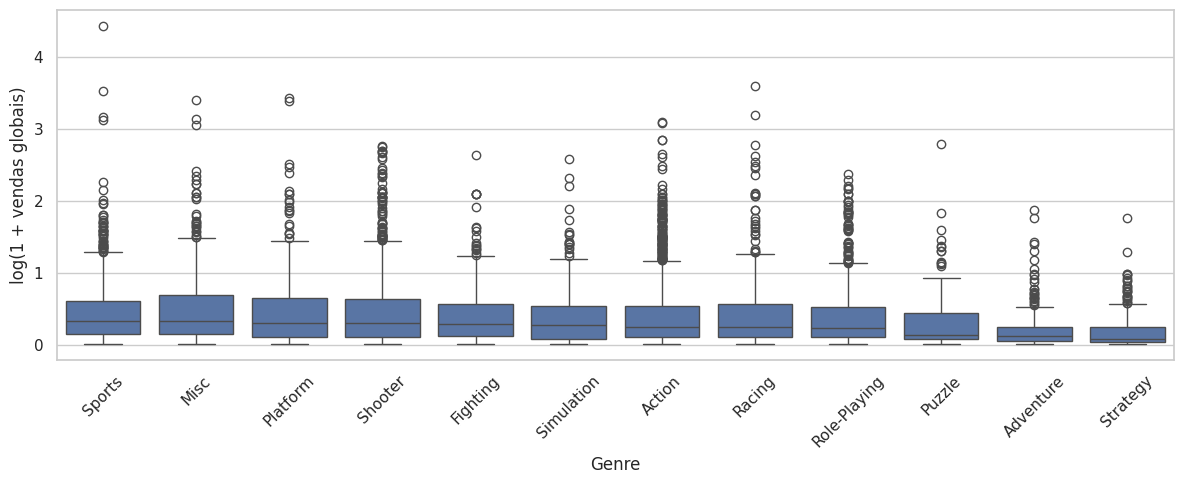

In [8]:
ordem = df_clean.groupby('Genre')['Log_Sales'].median().sort_values(ascending=False).index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_clean, x='Genre', y='Log_Sales', order=ordem)
plt.xticks(rotation=45)
plt.ylabel('log(1 + vendas globais)')
plt.tight_layout()
plt.show()

### 3.5 Correlações

**Objetivo:** medir a associação linear (Pearson) e monotônica (Spearman) entre as variáveis. Como as vendas são muito assimétricas, o Spearman serve de checagem de robustez. As vendas regionais (`NA_Sales`, `EU_Sales`, etc.) ficam de fora porque somam `Global_Sales` e a correlação com elas seria tautológica.

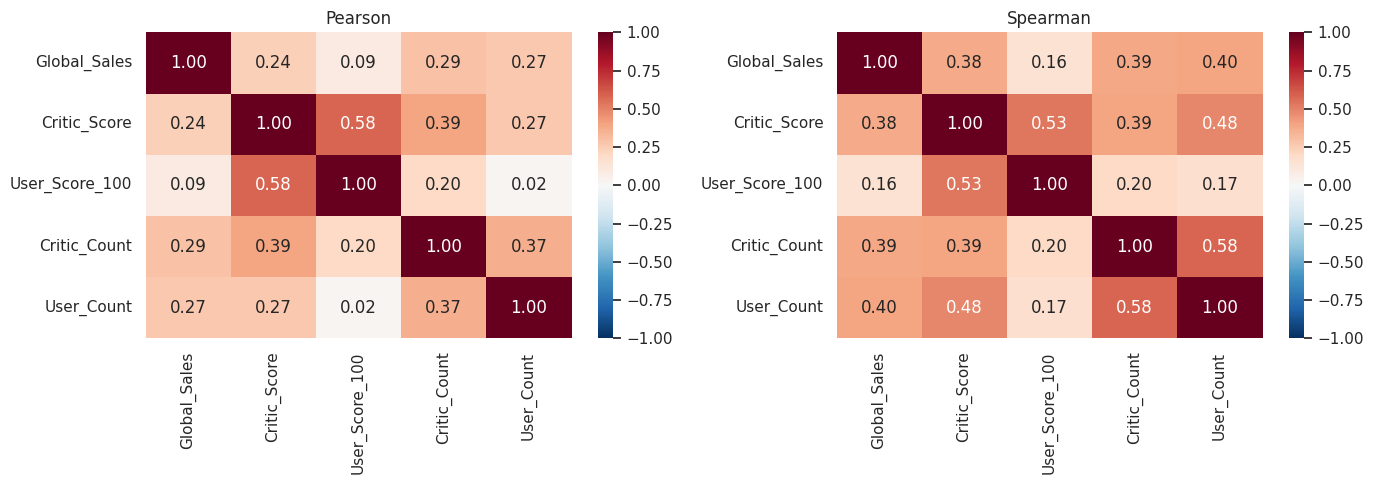

In [9]:
colunas_corr = ['Global_Sales', 'Critic_Score', 'User_Score_100', 'Critic_Count', 'User_Count']
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for eixo, metodo in zip(eixos, ['pearson', 'spearman']):
    sns.heatmap(df_clean[colunas_corr].corr(method=metodo), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=eixo)
    eixo.set_title(metodo.capitalize())
plt.tight_layout()
plt.show()

### 3.6 Divergência entre crítica e público

**Objetivo:** observar a distribuição de `Score_Diff` (crítica − público), que é a variável analisada no teste pareado da seção 4.

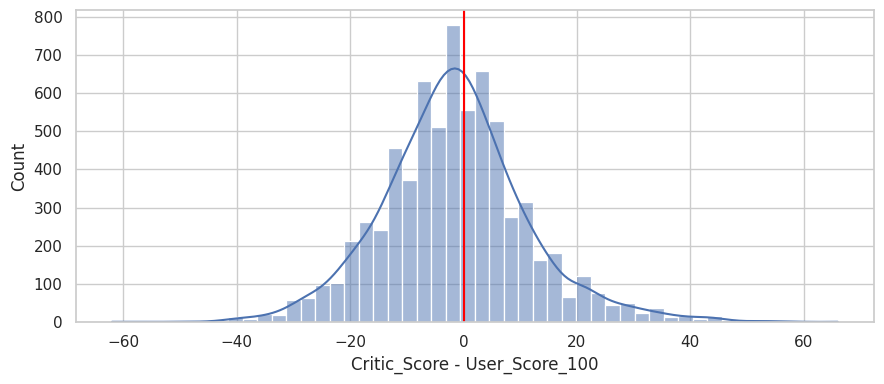

In [10]:
plt.figure(figsize=(9, 4))
sns.histplot(df_clean['Score_Diff'], bins=50, kde=True)
plt.axvline(0, color='red')
plt.xlabel('Critic_Score - User_Score_100')
plt.tight_layout()
plt.show()

## 4. Testes de hipóteses e intervalos de confiança

Em todos os testes usamos nível de significância **α = 0,05** (confiança de 95%). O p-valor mede a probabilidade de observar uma estatística tão extrema quanto a obtida se H₀ fosse verdadeira; rejeitamos H₀ quando p < α.

### 4.1 Teste 1: a crítica e o público pontuam, em média, o mesmo?

* **Hipóteses:** H₀: μ_crítica = μ_público contra H₁: μ_crítica ≠ μ_público (bilateral, pois não há direção esperada).
* **Teste escolhido: t de Student pareado.** Cada jogo tem as duas notas, então as amostras são dependentes. O teste trabalha sobre as diferenças `Score_Diff` e tem n − 1 graus de liberdade.
* **Pressupostos:** diferenças independentes entre jogos e distribuição aproximadamente normal. O histograma da seção 3.6 mostra a forma das diferenças, e com n da ordem de milhares o Teorema Central do Limite sustenta a normalidade da média amostral. Como checagem, aplicamos também o **teste de Wilcoxon** (não paramétrico).
* **Tamanho de efeito:** com n grande, diferenças minúsculas ficam significativas. Por isso reportamos o **d de Cohen pareado** (média das diferenças / desvio padrão das diferenças), que separa significância estatística de relevância prática.

In [11]:
diferenca = df_clean['Score_Diff']
n_pares = len(diferenca)
t1, p1 = stats.ttest_rel(df_clean['Critic_Score'], df_clean['User_Score_100'])
media_dif = diferenca.mean()
margem_dif = stats.sem(diferenca) * stats.t.ppf(0.975, n_pares - 1)
d_cohen = media_dif / diferenca.std(ddof=1)
w_stat, p_wilcoxon = stats.wilcoxon(diferenca)

teste1 = pd.Series({
    'n (pares)': n_pares,
    'graus de liberdade': n_pares - 1,
    'média crítica': df_clean['Critic_Score'].mean(),
    'média público': df_clean['User_Score_100'].mean(),
    'diferença média (crítica - público)': media_dif,
    'IC 95% inferior': media_dif - margem_dif,
    'IC 95% superior': media_dif + margem_dif,
    'estatística t': t1,
    'p-valor (t pareado)': p1,
    'p-valor (Wilcoxon)': p_wilcoxon,
    'd de Cohen pareado': d_cohen
}, name='Teste 1')
display(teste1.to_frame())

,Teste 1
n (pares),7007
graus de liberdade,7006
média crítica,70.31
média público,71.85
diferença média (crítica - público),-1.536
IC 95% inferior,-1.839
IC 95% superior,-1.232
estatística t,-9.909
p-valor (t pareado),5.375e-23
p-valor (Wilcoxon),5.695e-36


### 4.2 Teste 2: vendas médias de Shooter e Action

* **Motivação (vinda da análise descritiva, seção 3.1):** Action é o gênero mais numeroso e Shooter é o de maior média de vendas entre os gêneros bem definidos (Misc é uma categoria residual). A pergunta prática é se essa diferença de médias é estatisticamente distinguível.
* **Hipóteses:** H₀: μ_Shooter = μ_Action contra H₁: μ_Shooter ≠ μ_Action (bilateral).
* **Teste escolhido: t de Student para amostras independentes com correção de Welch** (`equal_var=False`). Os grupos são independentes e têm tamanhos e variâncias diferentes; o Levene abaixo avalia a igualdade de variâncias. Welch não assume variâncias iguais e usa graus de liberdade de Welch-Satterthwaite.
* **Robustez:** como as vendas são muito assimétricas, repetimos o Welch sobre `log(1 + vendas)` (compara médias na escala log) e aplicamos **Mann-Whitney** (não paramétrico, compara a tendência de um grupo ter valores maiores que o outro, sem comparar médias).
* **Intervalos de confiança:** IC 95% t para cada média e IC 95% de Welch para a diferença de médias.
* **Cuidado:** a escolha desses dois gêneros foi feita depois de olhar os dados descritivos (comparação *post hoc*). Isso aumenta o risco de falso positivo e é uma limitação a considerar na interpretação.

In [12]:
def ic_media(x, nivel=0.95):
    x = np.asarray(x, dtype=float)
    media = x.mean()
    margem = stats.sem(x) * stats.t.ppf((1 + nivel) / 2, len(x) - 1)
    return media, media - margem, media + margem


def ic_diferenca_welch(a, b, nivel=0.95):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    gl = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    dif = a.mean() - b.mean()
    margem = stats.t.ppf((1 + nivel) / 2, gl) * np.sqrt(va + vb)
    return dif, dif - margem, dif + margem, gl


vendas_shooter = df_clean.loc[df_clean['Genre'] == 'Shooter', 'Global_Sales']
vendas_action = df_clean.loc[df_clean['Genre'] == 'Action', 'Global_Sales']

print('Levene (igualdade de variâncias): p =', stats.levene(vendas_shooter, vendas_action)[1])

t_w, p_w = stats.ttest_ind(vendas_shooter, vendas_action, equal_var=False)
t_wl, p_wl = stats.ttest_ind(np.log1p(vendas_shooter), np.log1p(vendas_action), equal_var=False)
u_stat, p_u = stats.mannwhitneyu(vendas_shooter, vendas_action, alternative='two-sided')

dif, dif_inf, dif_sup, gl_welch = ic_diferenca_welch(vendas_shooter, vendas_action)

testes_genero = pd.DataFrame({
    'estatística': [t_w, t_wl, u_stat],
    'p-valor': [p_w, p_wl, p_u]
}, index=['Welch (vendas)', 'Welch (log das vendas)', 'Mann-Whitney (vendas)'])
display(testes_genero)

ics = pd.DataFrame(
    [ic_media(vendas_action), ic_media(vendas_shooter)],
    columns=['média', 'IC 95% inferior', 'IC 95% superior'], index=['Action', 'Shooter']
)
ics['mediana'] = [vendas_action.median(), vendas_shooter.median()]
ics['n'] = [len(vendas_action), len(vendas_shooter)]
display(ics)
print(f'Diferença de médias (Shooter - Action): {dif:.4f} | IC 95%: [{dif_inf:.4f}; {dif_sup:.4f}] | gl de Welch: {gl_welch:.1f}')

Levene (igualdade de variâncias): p = 0.0005157140897370761


,estatística,p-valor
Welch (vendas),3.052,0.002311
Welch (log das vendas),3.076,0.002133
Mann-Whitney (vendas),7.649e+05,0.163


,média,IC 95% inferior,IC 95% superior,mediana,n
Action,0.735,0.6644,0.8055,0.29,1667
Shooter,0.9551,0.8325,1.078,0.35,888


Diferença de médias (Shooter - Action): 0.2202 | IC 95%: [0.0787; 0.3616] | gl de Welch: 1484.9


## 5. Regressão linear múltipla

Variável resposta: vendas globais. Preditores: `Critic_Score`, `User_Score_100`, `Critic_Count` e `User_Count`. Estimamos por mínimos quadrados ordinários (OLS).

* **Modelo 1 (nível):** `Global_Sales` ~ preditores em escala original. É o modelo base e o mais fácil de interpretar (coeficiente = milhões de cópias por unidade do preditor).
* **Modelo 2 (log):** `log(1 + Global_Sales)` ~ notas + `log(1 + contagens)`. Construído depois do diagnóstico do Modelo 1, que mostra violação dos pressupostos (seção 5.2). Coeficientes de `log(1+y)` são aproximadamente variações relativas nas vendas para jogos de vendas maiores.

### 5.1 Ajuste do Modelo 1

In [13]:
colunas_m1 = ['Critic_Score', 'User_Score_100', 'Critic_Count', 'User_Count']
X1 = sm.add_constant(df_clean[colunas_m1])
y1 = df_clean['Global_Sales']
modelo1 = sm.OLS(y1, X1).fit()
print(modelo1.summary())

                            OLS Regression Results                            
Dep. Variable:           Global_Sales   R-squared:                       0.127
Model:                            OLS   Adj. R-squared:                  0.127
Method:                 Least Squares   F-statistic:                     255.1
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          6.16e-205
Time:                        23:17:05   Log-Likelihood:                -14167.
No. Observations:                7007   AIC:                         2.834e+04
Df Residuals:                    7002   BIC:                         2.838e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -0.9635      0.127     -7.

### 5.2 Diagnóstico dos pressupostos

Verificamos: **linearidade e homocedasticidade** (resíduos vs ajustados, teste de Breusch-Pagan, H₀: variância constante), **normalidade dos resíduos** (QQ-plot, assimetria e curtose) e **multicolinearidade** (VIF; valores acima de cerca de 5 a 10 indicam problema). O *Condition Number* alto do sumário OLS pode vir simplesmente da diferença de escala entre as variáveis; o VIF é o diagnóstico adequado de colinearidade.

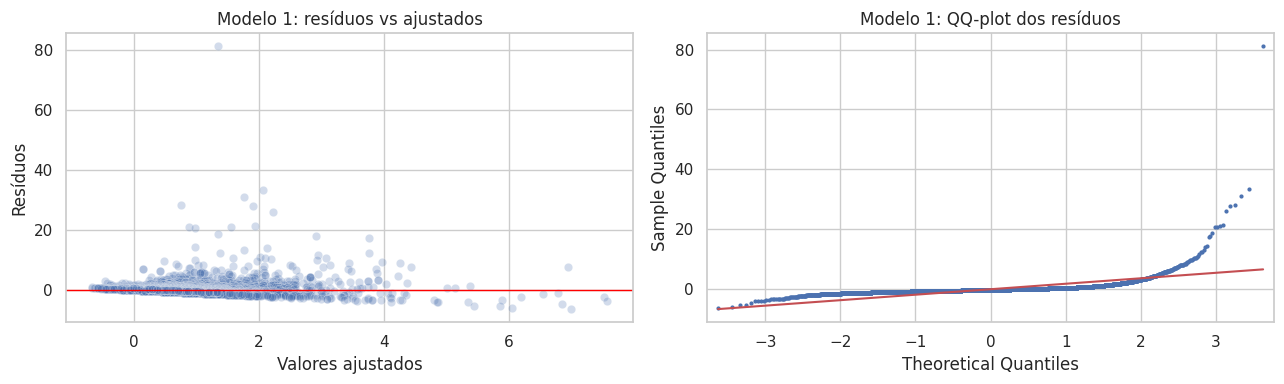

,Modelo 1
R2,0.1272
R2 ajustado,0.1267
p-valor do teste F,6.16e-205
Breusch-Pagan (p-valor),0.0005259
Assimetria dos resíduos,17.89
Curtose (excesso) dos resíduos,622.3
Condition Number,3554


,VIF
Critic_Score,1.796
User_Score_100,1.552
Critic_Count,1.296
User_Count,1.213


In [14]:
def diagnosticos(modelo, titulo):
    residuos = modelo.resid
    ajustados = modelo.fittedvalues
    fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
    sns.scatterplot(x=ajustados, y=residuos, alpha=0.25, ax=eixos[0])
    eixos[0].axhline(0, color='red', linewidth=1)
    eixos[0].set_xlabel('Valores ajustados')
    eixos[0].set_ylabel('Resíduos')
    eixos[0].set_title(f'{titulo}: resíduos vs ajustados')
    sm.qqplot(residuos, line='s', ax=eixos[1], markersize=2)
    eixos[1].set_title(f'{titulo}: QQ-plot dos resíduos')
    plt.tight_layout()
    plt.show()
    return {
        'R2': modelo.rsquared,
        'R2 ajustado': modelo.rsquared_adj,
        'p-valor do teste F': modelo.f_pvalue,
        'Breusch-Pagan (p-valor)': het_breuschpagan(residuos, modelo.model.exog)[1],
        'Assimetria dos resíduos': stats.skew(residuos),
        'Curtose (excesso) dos resíduos': stats.kurtosis(residuos),
        'Condition Number': modelo.condition_number
    }


def tabela_vif(X):
    return pd.Series({coluna: variance_inflation_factor(X.values, i)
                      for i, coluna in enumerate(X.columns) if coluna != 'const'}, name='VIF')


diag1 = diagnosticos(modelo1, 'Modelo 1')
display(pd.DataFrame({'Modelo 1': diag1}))
display(tabela_vif(X1).to_frame())

### 5.3 Modelo 2 (log) e comparação

Como o diagnóstico do Modelo 1 aponta resíduos assimétricos com caudas pesadas e variância não constante, ajustamos o Modelo 2 com a resposta e as contagens em log.

                            OLS Regression Results                            
Dep. Variable:              Log_Sales   R-squared:                       0.265
Model:                            OLS   Adj. R-squared:                  0.265
Method:                 Least Squares   F-statistic:                     631.0
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:17:06   Log-Likelihood:                -3382.8
No. Observations:                7007   AIC:                             6776.
Df Residuals:                    7002   BIC:                             6810.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -0.5783      0.030  

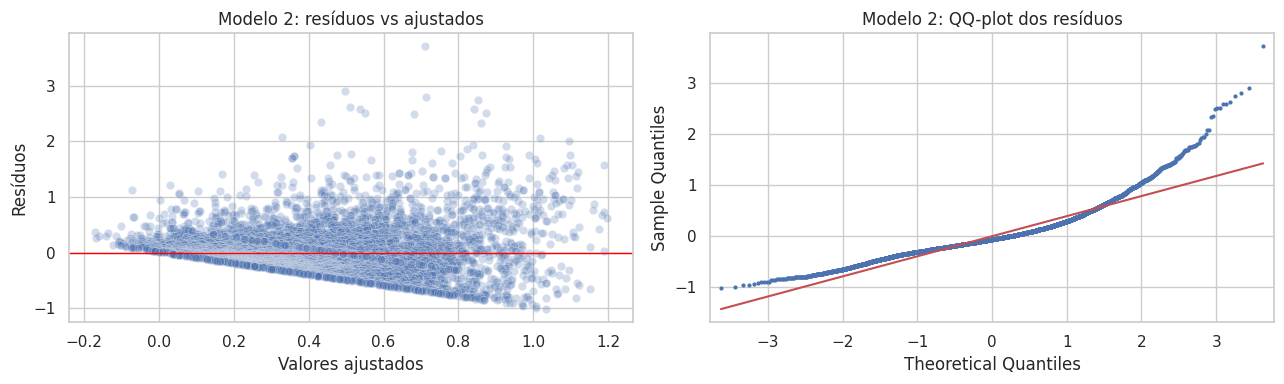

,Modelo 1,Modelo 2
R2,0.1272,0.265
R2 ajustado,0.1267,0.2645
p-valor do teste F,6.16e-205,0
Breusch-Pagan (p-valor),0.0005259,5.867e-136
Assimetria dos resíduos,17.89,1.672
Curtose (excesso) dos resíduos,622.3,6.428
Condition Number,3554,665.1


,VIF
Critic_Score,1.975
User_Score_100,1.578
Log_Critic_Count,1.529
Log_User_Count,1.685


In [15]:
colunas_m2 = ['Critic_Score', 'User_Score_100', 'Log_Critic_Count', 'Log_User_Count']
X2 = sm.add_constant(df_clean[colunas_m2])
y2 = df_clean['Log_Sales']
modelo2 = sm.OLS(y2, X2).fit()
print(modelo2.summary())

diag2 = diagnosticos(modelo2, 'Modelo 2')
display(pd.DataFrame({'Modelo 1': diag1, 'Modelo 2': diag2}))
display(tabela_vif(X2).to_frame())

O Modelo 2 reduz bastante a assimetria e a curtose dos resíduos e dobra o R², mas o teste de Breusch-Pagan continua rejeitando variância constante. A correção usual é reportar **erros-padrão robustos à heterocedasticidade (HC3)**: os coeficientes continuam os mesmos, mas os erros-padrão e p-valores passam a ser válidos sem a hipótese de variância constante. Se as conclusões não mudam, a inferência sobre os coeficientes é confiável apesar da violação.

In [16]:
modelo2_robusto = sm.OLS(y2, X2).fit(cov_type='HC3')
comparacao_ep = pd.DataFrame({
    'coeficiente': modelo2.params,
    'EP (OLS)': modelo2.bse,
    'EP (HC3)': modelo2_robusto.bse,
    'p-valor (OLS)': modelo2.pvalues,
    'p-valor (HC3)': modelo2_robusto.pvalues
})
display(comparacao_ep)

,coeficiente,EP (OLS),EP (HC3),p-valor (OLS),p-valor (HC3)
const,-0.5783,0.03024,0.02835,1.78e-79,1.73e-92
Critic_Score,0.006791,0.0004751,0.0004249,1.046e-45,1.762e-57
User_Score_100,-0.0009435,0.0004089,0.0003971,0.02107,0.0175
Log_Critic_Count,0.07307,0.008387,0.007985,3.674e-18,5.693e-20
Log_User_Count,0.09697,0.004033,0.004942,8.411e-123,9.926e-86


### 5.4 Validação em dados não vistos (treino e teste)

O R² dentro da amostra não mede capacidade de previsão. Separamos 80% dos jogos para ajustar e 20% para testar (`random_state=42` para reprodutibilidade) e comparamos **RMSE**, **MAE** e **R²** fora da amostra. O Modelo 2 é avaliado na escala log (onde foi ajustado) e também na escala original em milhões de cópias, após voltar com `expm1`, para comparação justa com o Modelo 1.

,RMSE,MAE,R2
"Modelo 1, treino (milhões)",1.917,0.712,0.1142
"Modelo 1, teste (milhões)",1.416,0.7115,0.2099
"Modelo 2, treino (escala log)",0.3913,0.272,0.2577
"Modelo 2, teste (escala log)",0.3959,0.2822,0.2902
"Modelo 2, teste (milhões)",1.466,0.6188,0.1537


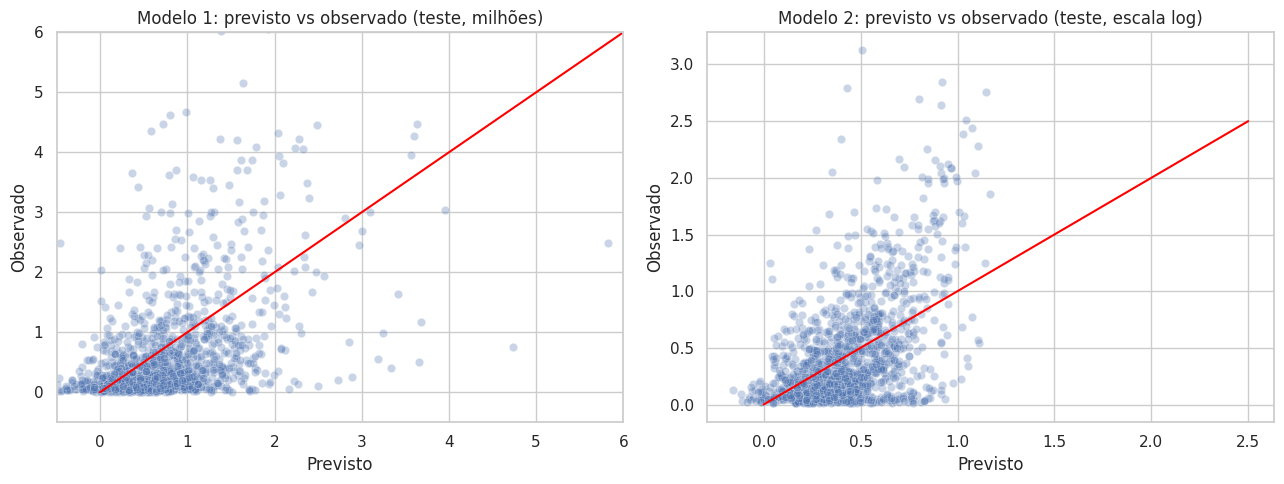

In [17]:
idx_treino, idx_teste = train_test_split(df_clean.index, test_size=0.2, random_state=42)
base_treino = df_clean.loc[idx_treino]
base_teste = df_clean.loc[idx_teste]


def metricas(real, previsto):
    erro = real - previsto
    return {
        'RMSE': np.sqrt((erro ** 2).mean()),
        'MAE': erro.abs().mean(),
        'R2': 1 - (erro ** 2).sum() / ((real - real.mean()) ** 2).sum()
    }


def treinar(colunas, alvo):
    Xtr = sm.add_constant(base_treino[colunas])
    Xte = sm.add_constant(base_teste[colunas], has_constant='add')
    modelo = sm.OLS(base_treino[alvo], Xtr).fit()
    return modelo.predict(Xtr), modelo.predict(Xte)


p1_tr, p1_te = treinar(colunas_m1, 'Global_Sales')
p2_tr, p2_te = treinar(colunas_m2, 'Log_Sales')

validacao = pd.DataFrame({
    'Modelo 1, treino (milhões)': metricas(base_treino['Global_Sales'], p1_tr),
    'Modelo 1, teste (milhões)': metricas(base_teste['Global_Sales'], p1_te),
    'Modelo 2, treino (escala log)': metricas(base_treino['Log_Sales'], p2_tr),
    'Modelo 2, teste (escala log)': metricas(base_teste['Log_Sales'], p2_te),
    'Modelo 2, teste (milhões)': metricas(base_teste['Global_Sales'], np.expm1(p2_te).clip(lower=0))
}).T
display(validacao)

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=p1_te, y=base_teste['Global_Sales'], alpha=0.3, ax=eixos[0])
eixos[0].plot([0, 6], [0, 6], color='red')
eixos[0].set_xlim(-0.5, 6)
eixos[0].set_ylim(-0.5, 6)
eixos[0].set_title('Modelo 1: previsto vs observado (teste, milhões)')
sns.scatterplot(x=p2_te, y=base_teste['Log_Sales'], alpha=0.3, ax=eixos[1])
eixos[1].plot([0, 2.5], [0, 2.5], color='red')
eixos[1].set_title('Modelo 2: previsto vs observado (teste, escala log)')
for eixo in eixos:
    eixo.set_xlabel('Previsto')
    eixo.set_ylabel('Observado')
plt.tight_layout()
plt.show()

### 5.5 Previsão para um novo lançamento

Jogo hipotético: nota 85 da crítica, nota 80 do público (8,0 na escala original), 60 avaliações de críticos e 500 avaliações de usuários. Além da previsão pontual, reportamos o **intervalo de predição de 95%**, que cobre o valor de um jogo individual e é bem mais largo que o intervalo de confiança da média. Para o Modelo 2, os limites são trazidos de volta à escala original com `expm1`.

In [18]:
novo = {'Critic_Score': 85.0, 'User_Score_100': 80.0, 'Critic_Count': 60.0, 'User_Count': 500.0}

x_novo1 = pd.DataFrame([{'const': 1.0, **{c: novo[c] for c in colunas_m1}}])
x_novo2 = pd.DataFrame([{
    'const': 1.0,
    'Critic_Score': novo['Critic_Score'],
    'User_Score_100': novo['User_Score_100'],
    'Log_Critic_Count': np.log1p(novo['Critic_Count']),
    'Log_User_Count': np.log1p(novo['User_Count'])
}])

pred1 = modelo1.get_prediction(x_novo1).summary_frame(alpha=0.05).iloc[0]
pred2 = modelo2.get_prediction(x_novo2).summary_frame(alpha=0.05).iloc[0]

previsao = pd.DataFrame({
    'Modelo 1': [pred1['mean'], pred1['obs_ci_lower'], pred1['obs_ci_upper']],
    'Modelo 2': [np.expm1(pred2['mean']), np.expm1(pred2['obs_ci_lower']), np.expm1(pred2['obs_ci_upper'])]
}, index=['Previsão (milhões de cópias)', 'Intervalo de predição 95% (inferior)', 'Intervalo de predição 95% (superior)'])
display(previsao)

,Modelo 1,Modelo 2
Previsão (milhões de cópias),1.787,1.286
Intervalo de predição 95% (inferior),-1.798,0.05911
Intervalo de predição 95% (superior),5.372,3.932


## 6. Conclusões, recomendações e limitações

### 6.1 Principais resultados

**Dados.** A análise usa 7.007 jogos avaliados (41,4% da base original). A média de vendas dessa amostra (0,78 milhão) é maior que a da base completa (0,54 milhão), efeito do viés de seleção descrito na seção 1. As vendas são extremamente assimétricas (assimetria 15,9, que cai para 2,23 com log), e apenas 18,95% dos jogos atingem 1 milhão de cópias.

**Teste 1 (crítica vs público).** Rejeita-se H₀ (t = −9,91; gl = 7.006; p = 5,4 × 10⁻²³; Wilcoxon concorda, p = 5,7 × 10⁻³⁶). A crítica pontua em média 1,54 ponto abaixo do público (70,31 vs 71,85; IC 95% da diferença: [−1,84; −1,23]). O d de Cohen pareado é −0,12, ou seja, um efeito **pequeno**: a diferença é estatisticamente clara, porém pequena na prática.

**Teste 2 (Shooter vs Action).** Médias de 0,96 milhão (IC 95% [0,83; 1,08]) para Shooter e 0,73 milhão (IC 95% [0,66; 0,81]) para Action. A diferença de médias é 0,22 milhão (IC 95% [0,08; 0,36], sem incluir zero) e o Welch rejeita H₀ (p = 0,0023; na escala log, p = 0,0021). **Porém** o Mann-Whitney não rejeita (p = 0,163) e as medianas são próximas (0,35 vs 0,29). A leitura consistente é que a vantagem de Shooter está na média, puxada pela cauda superior (poucos grandes sucessos), e não em um resultado típico melhor. A evidência a favor de Shooter é, portanto, parcial.

**Regressão.**
* *Modelo 1 (nível):* R² = 12,7%; F significativo (p = 6,2 × 10⁻²⁰⁵). Cada ponto na nota da crítica se associa a cerca de +19.800 cópias (β = 0,0198), cada avaliação adicional da crítica a +18.300 cópias e cada avaliação do público a +600 cópias. A nota do público tem coeficiente pequeno e negativo (β = −0,0038; p = 0,044), efeito **parcial** condicionado às demais variáveis, e não indica que notas altas do público reduzam vendas.
* *Diagnóstico do Modelo 1:* resíduos muito assimétricos (assimetria 17,9; curtose em excesso 622) e variância não constante (Breusch-Pagan p < 0,001). O VIF é no máximo 1,8, logo **não há multicolinearidade relevante**; o Condition Number de 3.554 reflete a diferença de escala entre as variáveis.
* *Modelo 2 (log):* R² = 26,5%, assimetria dos resíduos cai para 1,67 e a curtose para 6,4. Todos os coeficientes mantêm a significância com erros-padrão robustos (HC3), embora a heterocedasticidade persista.
* *Fora da amostra (20% de teste):* Modelo 2 com R² = 0,29 e MAE = 0,28 na escala log; na escala original, MAE = 0,62 milhão contra 0,71 milhão do Modelo 1. O R² de teste do Modelo 1 (0,21) superior ao de treino (0,11) decorre de os outliers de venda extrema estarem concentrados no treino e não deve ser lido como bom desempenho.
* *Previsão do jogo hipotético:* Modelo 2 prevê 1,29 milhão de cópias (intervalo de predição 95%: [0,06; 3,93]). O Modelo 1 prevê 1,79 milhão com intervalo [−1,80; 5,37], cujo limite negativo é impossível e confirma sua inadequação para previsão individual.

### 6.2 Recomendações práticas

1. **Portfólio de gêneros.** Shooter oferece **maior potencial médio** que Action, mas com a vantagem concentrada nos grandes sucessos; não há garantia de resultado típico melhor. É uma aposta de maior retorno potencial e maior risco. Já Adventure e Strategy têm médias baixas (cerca de 0,31 e 0,25 milhão) e só 6,0% e 5,4% dos títulos chegam a 1 milhão de cópias, o que justifica expectativas mais conservadoras de vendas nesses gêneros.
2. **Qualidade e cobertura crítica.** Nota da crítica e número de avaliações da crítica estão positivamente associados às vendas, mesmo com o controle das demais variáveis. Priorizar qualidade e garantir cobertura da imprensa no lançamento é coerente com os dados, mas a relação é de **associação**: jogos já grandes tendem a receber mais cobertura, então o ganho causal de investir em imprensa não está identificado.
3. **Triagem de projetos.** O Modelo 2 pode ordenar projetos por vendas esperadas, sempre acompanhado do intervalo de predição, que é largo. Serve para comparar candidatos, não para fixar metas de vendas.

### 6.3 Limitações

* **Viés de seleção:** 58,6% dos jogos foram descartados por não terem notas; as conclusões valem para jogos avaliados.
* **Variável resposta:** são unidades vendidas, não receita nem lucro. Orçamento, marketing, franquia e microtransações não estão na base.
* **Capacidade explicativa limitada:** mesmo o melhor modelo explica cerca de um quarto da variação (log), e os resíduos ainda têm cauda pesada e variância não constante.
* **Causalidade:** os resultados são observacionais; `Critic_Count` pode refletir o porte do projeto.
* **Comparação de gêneros *post hoc*:** Shooter e Action foram escolhidos depois de ver os dados, sem correção para múltiplas comparações; com n grande, significância não implica relevância prática.
* **Validação:** uma única divisão treino/teste; validação cruzada seria mais estável.
* **Período:** a base termina em 2016, antes da consolidação de vendas digitais e jogos como serviço.

## 7. Exportação dos dados tratados para o dashboard

In [19]:
df_clean.to_csv('Video_Games_Clean.csv', index=False)
print(df_clean.shape)

(7007, 23)
